# Does training augmentation help underwater segmentation?

Compare the existing augmented CNN, transformer, and hybrid runs with new runs
that disable augmentation. Each model starts from its original ImageNet weights
and the same seed (42). Training uses the same cleaned data, 1,220/305 split,
320 x 240 inputs, batch size 2, AdamW settings, and 50-epoch budget. Validation
loss selects the checkpoint separately for each run. TEST never selects weights
or hyperparameters.

This tests the existing horizontal flips and small affine changes as one
augmentation policy. It does not test color, visibility, or additional underwater
augmentation. It also does not isolate individual transforms.

The primary comparison uses 106 TEST images after excluding the four known exact
training-pool overlaps. The original 110-image scores are retained. Metrics are
the existing five-class per-image IoU and boundary F-score, macro-averaged across
classes with absent-class images skipped, rather than eight-class mIoU.

The completed augmented runs are reused. The authors' pretrained U-Net is
excluded from this paired comparison because its training conditions differ.

## Environment and files

Use **Python (SUIM U-Net ResNet18)** (`.venv-segformer`), which has dependencies
for all three models. This notebook imports `scripts/augmentation_experiment.py`.
The runner executes fresh copies of notebooks 03, 04, and 05; their architecture,
training, prediction, metric code, and license notices are retained. It overrides
augmentation and output paths, verifies the shared settings, and asserts that
the actual data loaders have augmentation disabled.

Predictions: `data/test/output/<model>_noaug/`.
Checkpoints: `ckpt/<model>_noaug/best.pt`.
Executed trial notebooks: `artifacts/augmentation_experiment/runs/`.
Comparison and per-class CSV reports: `artifacts/augmentation_experiment/`.
The original augmented outputs and notebooks are checked for changes.

In [1]:
from pathlib import Path
import subprocess
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'scripts/augmentation_experiment.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from the local SUIM project.')
sys.path.insert(0, str(ROOT / 'scripts'))
from augmentation_experiment import MODELS, PRIMARY, preflight, collect_results, report_dir


In [2]:
baselines = preflight(ROOT)
display(pd.DataFrame([
    {'model': name, 'augmentation': result['checkpoint_metadata']['use_augmentation'],
     'epochs': result['epochs_requested'], 'seed': result['seed'],
     'train_pairs': result['train_pairs'], 'validation_pairs': result['validation_pairs'],
     'best_epoch': result['checkpoint_metadata']['epoch']}
    for name, result in baselines.items()
]))

,model,augmentation,epochs,seed,train_pairs,validation_pairs,best_epoch
0,unet_resnet18,True,50,42,1220,305,34
1,segformer_b0,True,50,42,1220,305,13
2,unetformer_resnet18,True,50,42,1220,305,43


## Optional training

The next cell defaults to reading saved results. Change `RUN_TRAINING` to `True`
only to launch missing no-augmentation trials. They train sequentially on one GPU
and may take several hours. Existing completed trial reports are protected from
accidental retraining. For a single model, shorten `MODELS_TO_RUN`.

Equivalent command from the project root:

```powershell
.\.venv-segformer\Scripts\python.exe scripts\augmentation_experiment.py
```

Use `--report-only` to refresh the comparison without training. Training restarts
from ImageNet; it does not continue from an augmented SUIM checkpoint.

In [3]:
RUN_TRAINING = False
MODELS_TO_RUN = list(MODELS)  # CNN, SegFormer-B0, UNetFormer-ResNet18

In [4]:
if RUN_TRAINING:
    for name in MODELS_TO_RUN:
        if name not in MODELS:
            raise ValueError(f'Unknown model: {name}')
        subprocess.run([sys.executable, str(ROOT / 'scripts/augmentation_experiment.py'),
                        '--root', str(ROOT), '--model', name], check=True, cwd=ROOT)
else:
    print('Reading saved results. Set RUN_TRAINING = True to launch missing trials.')

Reading saved results. Set RUN_TRAINING = True to launch missing trials.


## Matched results

Positive gains mean **augmentation helped**: augmented score minus
no-augmentation score in percentage points. Negative gains favor training
without augmentation. Pending rows are not results.

Both conditions use one seed. Small differences do not demonstrate a reliable
advantage, and this experiment only supports conclusions about the tested
augmentation policy and model configurations. The hybrid retains its auxiliary
training loss in both conditions; comparisons of augmentation are within model.

In [5]:
comparison = collect_results(ROOT)
primary = comparison.loc[comparison.protocol == PRIMARY].copy()
display(primary[['model', 'status', 'test_images', 'augmented_iou_pct', 'noaug_iou_pct',
                 'augmentation_iou_gain_pp', 'augmented_boundary_f_pct',
                 'noaug_boundary_f_pct', 'augmentation_boundary_f_gain_pp',
                 'augmented_best_epoch', 'noaug_best_epoch']].round(3))
print('Saved reports:', report_dir(ROOT))
print('Completed models:', int((primary.status == 'complete').sum()), '/', len(MODELS))

,model,status,test_images,augmented_iou_pct,noaug_iou_pct,augmentation_iou_gain_pp,augmented_boundary_f_pct,noaug_boundary_f_pct,augmentation_boundary_f_gain_pp,augmented_best_epoch,noaug_best_epoch
0,unet_resnet18,complete,106,57.953,41.549,16.404,51.658,37.108,14.550,34,19
2,segformer_b0,complete,106,53.113,52.715,0.398,46.859,46.084,0.775,13,9
4,unetformer_resnet18,complete,106,57.359,56.037,1.322,52.923,50.356,2.567,43,25


Saved reports: C:\Users\darre\OneDrive\Desktop\SUIM\artifacts\augmentation_experiment
Completed models: 3 / 3


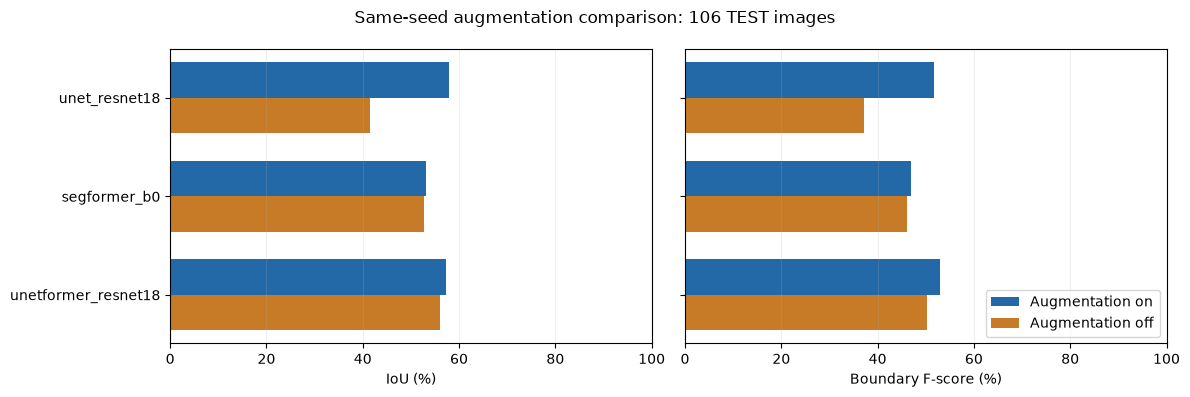

In [6]:
completed = primary.loc[primary.status == 'complete'].reset_index(drop=True)
if len(completed):
    figure, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
    positions = list(range(len(completed)))
    for axis, metric, title in zip(axes, ['iou', 'boundary_f'], ['IoU (%)', 'Boundary F-score (%)']):
        axis.barh([p - 0.18 for p in positions], completed[f'augmented_{metric}_pct'],
                  height=0.36, label='Augmentation on', color='#2369a7')
        axis.barh([p + 0.18 for p in positions], completed[f'noaug_{metric}_pct'],
                  height=0.36, label='Augmentation off', color='#c77b26')
        axis.set_yticks(positions, completed.model)
        axis.set_xlim(0, 100)
        axis.set_xlabel(title)
        axis.grid(axis='x', alpha=0.2)
    axes[0].invert_yaxis()
    axes[1].legend(loc='lower right')
    figure.suptitle('Same-seed augmentation comparison: 106 TEST images')
    figure.tight_layout()
    figure.savefig(report_dir(ROOT) / 'augmentation_comparison.png', dpi=160, bbox_inches='tight')
    plt.show()
else:
    print('The comparison plot will appear once at least one full trial finishes.')

## Results from the completed runs

All three no-augmentation trials completed 50 GPU epochs. Each condition selected
its own best checkpoint using validation loss, with the same seed and training
settings within each model.

On the 106-image primary test subset, augmentation increased IoU by **16.40
percentage points for U-Net-ResNet18**, **0.40 for SegFormer-B0**, and **1.32 for
UNetFormer-ResNet18**. Boundary F-score increased by **14.55**, **0.78**, and
**2.57** points, respectively.

The CNN benefited most from this particular policy in these runs. Without
augmentation, the hybrid had the highest IoU of the three; with augmentation,
the CNN had the highest IoU. This shows why both model choice and training policy
matter in the comparison. One seed does not establish statistical reliability,
particularly for the small transformer and hybrid IoU gains. These results do
not measure other augmentation policies or isolate individual transforms.

The full 110-image reference scores, per-class results, and executed trial
notebooks are saved alongside the comparison reports.